# CNN ile Yüz Maskesi Tespiti

## Proje Hakkında

Bu projede Evrişimsel Sinir Ağları (CNN) kullanılarak yüz maskesi
kullanım durumları üç sınıfta sınıflandırılmıştır:

- Doğru Maske
- Maskesiz
- Yanlış Maske

Proje kapsamında veri ön işleme, veri artırma, CNN mimarisi
tasarımı, model eğitimi ve performans değerlendirme çalışmaları
gerçekleştirilmiştir.

**Kullanılan teknolojiler:** Python, TensorFlow, Keras, NumPy,
Matplotlib ve Scikit-learn.

**Veri seti:** 4.478 görsel (2.984 eğitim, 1.494 değerlendirme).

---


## 1. Kütüphanelerin Kurulması ve Ortamın Hazırlanması

In [ ]:
!pip install tensorflow opencv-python matplotlib


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r /content/drive/MyDrive/maske_proje/veriler /content/ #drive üzerinden colab kütüphanesine aktardık daha hızlı olması için.

## 2. Veri Seti Yollarının Tanımlanması

In [ ]:
train_path = '/content/drive/MyDrive/maske_proje/veriler/train'
test_path = '/content/drive/MyDrive/maske_proje/veriler/test'

## 3. Veri Ön İşleme ve Görüntü Artırma

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = 128  # Görsel boyutu

# Eğitim verisi için augmentasyon
train_datagen = ImageDataGenerator(
    rescale=1./255, #0-1 piksel üzerinde işliyor.
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

# Test verisi normalleştirme
test_datagen = ImageDataGenerator(rescale=1./255)

# Drive'daki  klasörlerden veri yükleme train
train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/maske_proje/veriler/train',
    target_size=(img_size, img_size),
    batch_size=64, #32
    class_mode='categorical'
)
# Drive'daki  klasörlerden veri yükleme test
test_generator = test_datagen.flow_from_directory(
    '/content/drive/MyDrive/maske_proje/veriler/test',
    target_size=(img_size, img_size),
    batch_size=64, #32
    class_mode='categorical'
)

Found 3000 images belonging to 3 classes.
Found 1496 images belonging to 3 classes.


## 4. İlk CNN Modeli

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Model tanımı
model = Sequential([
    # 1. Konvolüsyon + Havuzlama
    Conv2D(32, (3, 3), activation='relu', input_shape=(img_size, img_size, 3)),
    MaxPooling2D(2, 2),

    # 2. Konvolüsyon + Havuzlama
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # 3. Konvolüsyon + Havuzlama
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),

    # Tam bağlantılı katman (dense)
    Dense(128, activation='relu'),
    Dropout(0.5),  # Aşırı öğrenmeyi engellemek için kullandık.

    # Çıkış katmanı (3 sınıf için softmax)
    Dense(3, activation='softmax')
])

# Derleme (compile) işlemi
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Modelin özeti
model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print(train_generator.class_indices)

{'dogru_maske': 0, 'maskesiz': 1, 'yanlis_maske': 2}


In [ ]:
history = model.fit(  #veri 1
    train_generator,
    epochs=10,
    validation_data=test_generator
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 1310s 14s/step - accuracy: 0.4096 - loss: 1.0708 - val_accuracy: 0.5983 - val_loss: 0.9314
Epoch 2/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 347s 4s/step - accuracy: 0.6782 - loss: 0.7541 - val_accuracy: 0.5421 - val_loss: 1.1006
Epoch 3/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 329s 4s/step - accuracy: 0.7054 - loss: 0.7234 - val_accuracy: 0.6397 - val_loss: 0.9275
Epoch 4/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 334s 4s/step - accuracy: 0.7375 - loss: 0.6046 - val_accuracy: 0.6618 - val_loss: 0.9726
Epoch 5/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 326s 3s/step - accuracy: 0.7660 - loss: 0.5772 - val_accuracy: 0.6765 - val_loss: 0.9508
Epoch 6/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 329s 3s/step - accuracy: 0.7801 - loss: 0.5387 - val_accuracy: 0.7019 - val_loss: 1.0180
Epoch 7/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 335s 4s/step - accuracy: 0.8140 - loss: 0.4838 - val_accuracy: 0.6932 - val_loss: 1.1141
Epoch 8/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 325s 3s/step - accuracy: 0.8246 - loss: 0.4557 - val_accuracy: 0.7159 -

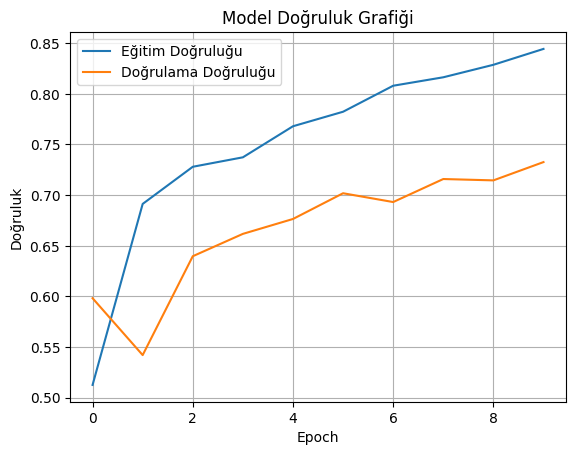

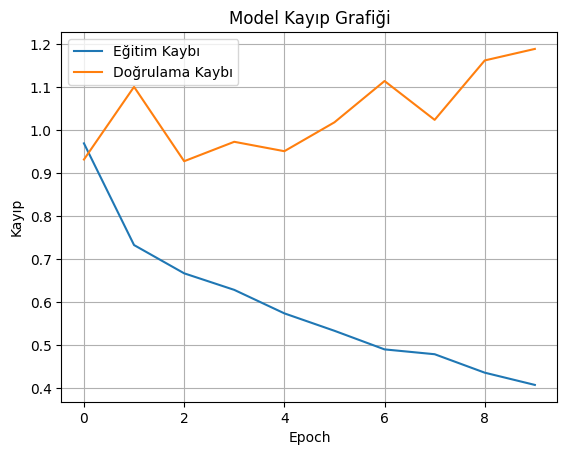

In [ ]:
import matplotlib.pyplot as plt

# Doğruluk
plt.plot(history.history['accuracy'], label='Eğitim Doğruluğu')
plt.plot(history.history['val_accuracy'], label='Doğrulama Doğruluğu')
plt.xlabel('Epoch')
plt.ylabel('Doğruluk')
plt.title('Model Doğruluk Grafiği')
plt.legend()
plt.grid(True)
plt.show()

# Kayıp
plt.plot(history.history['loss'], label='Eğitim Kaybı')
plt.plot(history.history['val_loss'], label='Doğrulama Kaybı')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.title('Model Kayıp Grafiği')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
loss, accuracy = model.evaluate(test_generator)
print(f"Test Doğruluğu: {accuracy:.4f}")
print(f"Test Kaybı: {loss:.4f}")

47/47 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.7388 - loss: 1.2149
Test Doğruluğu: 0.7326
Test Kaybı: 1.1888


In [ ]:
model.save('/content/drive/MyDrive/maske_proje/mask_model.h5')#modeli drive üzerine kaydettik

In [ ]:
import cv2  #test kodu ekstra
import numpy as np
from tensorflow.keras.preprocessing import image

# Drive içindeki yol
img_path = '/content/drive/MyDrive/maske_proje/soulmateveriler12.jpg'

# Görseli yükledik ve yeniden boyutlandırdık.
img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # (1, 128, 128, 3)
img_array = img_array / 255.0  # Normalize

# Tahmin
prediction = model.predict(img_array)
class_index = np.argmax(prediction)

# Etiket eşleme
etiketler = {0: 'dogru_maske', 1: 'maskesiz', 2: 'yanlis_maske'}
tahmin = etiketler[class_index]

print(f"Tahmin edilen sınıf: {tahmin}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
Tahmin edilen sınıf: dogru_maske


## 5. Geliştirilmiş CNN Modeli

In [ ]:
from tensorflow.keras.models import Sequential #veri2
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.3),

    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,585,667 (17.49 MB)

 Trainable params: 4,584,707 (17.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
history = model.fit(
    train_generator,
    epochs=15,
    validation_data=test_generator
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 1307s 14s/step - accuracy: 0.4755 - loss: 4.3233 - val_accuracy: 0.4017 - val_loss: 1.7628
Epoch 2/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 164s 2s/step - accuracy: 0.6646 - loss: 0.7887 - val_accuracy: 0.3356 - val_loss: 2.2394
Epoch 3/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.7109 - loss: 0.7265 - val_accuracy: 0.4652 - val_loss: 1.4801
Epoch 4/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 164s 2s/step - accuracy: 0.7324 - loss: 0.6583 - val_accuracy: 0.4024 - val_loss: 1.2869
Epoch 5/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 163s 2s/step - accuracy: 0.7568 - loss: 0.6204 - val_accuracy: 0.4759 - val_loss: 2.0210
Epoch 6/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.7742 - loss: 0.5590 - val_accuracy: 0.6357 - val_loss: 1.5728
Epoch 7/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.7780 - loss: 0.6062 - val_accuracy: 0.5221 - val_loss: 1.6318
Epoch 8/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 163s 2s/step - accuracy: 0.7997 - loss: 0.5403 - val_accuracy: 0.6999 -

In [ ]:
loss, accuracy = model.evaluate(test_generator)
print(f"Test Doğruluğu: {accuracy:.4f}")
print(f"Test Kaybı: {loss:.4f}")

47/47 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.7279 - loss: 1.5648
Test Doğruluğu: 0.7299
Test Kaybı: 1.4906


Saving soulmateveriler (12).jpg to soulmateveriler (12) (1).jpg


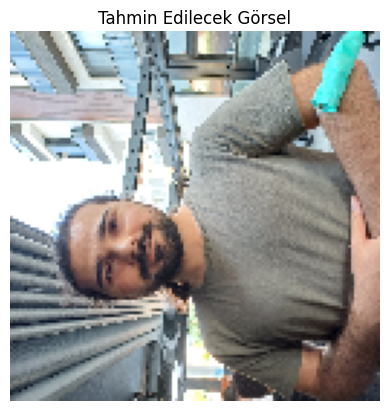

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Tahmin edilen sınıf: yanlis_maske
Tahmin olasılıkları: [0.2838433  0.08217913 0.6339776 ]


In [ ]:
# Gerekli kütüphaneler
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# Görsel yükleme
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Görseli işleme
img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # (1, 128, 128, 3)
img_array = img_array / 255.0  # Normalizasyon

# Görseli gösterme
plt.imshow(img)
plt.axis('off')
plt.title("Tahmin Edilecek Görsel")
plt.show()

# Tahmin yapma
predictions = model.predict(img_array)
predicted_class_index = np.argmax(predictions[0])

# Sınıf etiketleri
class_labels = ['dogru_maske', 'maskesiz', 'yanlis_maske']
tahmin = class_labels[predicted_class_index]


print(f"Tahmin edilen sınıf: {tahmin}")
print(f"Tahmin olasılıkları: {predictions[0]}")

In [ ]:
model.save('/content/drive/MyDrive/maske_proje/maskemodel_gelistirilmis.h5')

## 6. Alternatif CNN Modeli

In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

#  Klasör yolları
train_path = '/content/drive/MyDrive/maske_proje/veriler/train'
test_path = '/content/drive/MyDrive/maske_proje/veriler/test'

# Görsel boyutu ve batch ayarı
img_size = 64
batch_size = 256

#  Veri artırma
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical'
)
test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical'
)

#  CNN Model
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(img_size, img_size, 3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax')
])

# Derleme
model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

#  Eğitim
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=test_generator,
    callbacks=[early_stop]
)


Found 3000 images belonging to 3 classes.
Found 1494 images belonging to 3 classes.
Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 186s 16s/step - accuracy: 0.3415 - loss: 1.1011 - val_accuracy: 0.3340 - val_loss: 1.0989
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 160s 14s/step - accuracy: 0.3475 - loss: 1.0965 - val_accuracy: 0.3333 - val_loss: 1.0959
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 155s 13s/step - accuracy: 0.3429 - loss: 1.0964 - val_accuracy: 0.3775 - val_loss: 1.0940
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 157s 14s/step - accuracy: 0.3799 - loss: 1.0927 - val_accuracy: 0.3876 - val_loss: 1.0921
Epoch 5/20
 9/12 ━━━━━━━━━━━━━━━━━━━━ 23s 8s/step - accuracy: 0.4173 - loss: 1.0894

KeyboardInterrupt: 

In [ ]:
model.save('/content/drive/MyDrive/maske_proje/maskemli_gelistirilmis.h5')

In [ ]:
loss, acc = model.evaluate(test_generator)
print(f"Test Doğruluğu: {acc:.4f}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.6466 - loss: 0.8745
Test Doğruluğu: 0.6324


Saving soulmateveriler (12).jpg to soulmateveriler (12) (2).jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


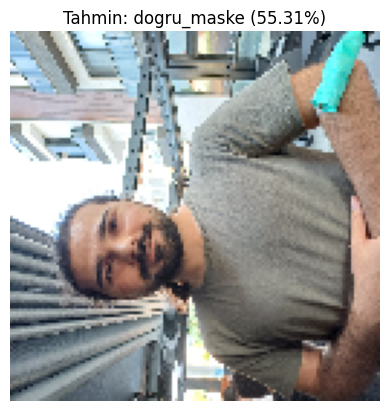

🔎 Sınıf Olasılıkları:
dogru_maske : 55.31%
maskesiz    : 26.53%
yanlis_maske: 18.16%


In [ ]:
#  Gerekli kütüphaneler
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Görsel yükleme
uploaded = files.upload()
if uploaded:
    img_path = list(uploaded.keys())[0]  # İlk yüklenen görsel

    # 📐 Görseli işleyip normalize ettik (modelin giriş boyutuna uygun)
    img = image.load_img(img_path, target_size=(128, 128))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0

    # 🎯 Tahmin yapma
    predictions = model.predict(img_array)
    predicted_class_index = np.argmax(predictions[0])
    confidence = np.max(predictions[0]) * 100

    #  Sınıf etiketleri (eğitime göre)
    class_labels = ['dogru_maske', 'maskesiz', 'yanlis_maske']
    tahmin = class_labels[predicted_class_index]

    # Sonuç görsel
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Tahmin: {tahmin} ({confidence:.2f}%)")
    plt.show()

    print("🔎 Sınıf Olasılıkları:")
    for i, label in enumerate(class_labels):
        print(f"{label:12}: {predictions[0][i]*100:.2f}%")

else:
    print("⚠️ Hiç görsel yüklenmedi.")


## 7. Dördüncü Deneysel Model

Bu modelde Mixed Precision, tf.data veri pipeline optimizasyonları ve EarlyStopping kullanılmıştır.

**Not:** Eğitim çıktıları eksik kaydedildiğinden modelin performansı doğrulanamamıştır. Bu nedenle diğer modellerin performans karşılaştırmasına dahil edilmemiştir.

In [ ]:
# Kütüphaneler
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import mixed_precision

# 🎯 Karma hassasiyet aktif
mixed_precision.set_global_policy('mixed_float16')


train_path = '/content/drive/MyDrive/maske_proje/veriler/train'
test_path = '/content/drive/MyDrive/maske_proje/veriler/test'

# 🔧 Ayarlar
img_size = 96
batch_size = 128
epochs = 20

# 🔁 Dataset yükleme
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(img_size, img_size),
    batch_size=batch_size,
    label_mode='categorical'
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(img_size, img_size),
    batch_size=batch_size,
    label_mode='categorical'
)

# Performans optimizasyonu
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

# 🧠 Model
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_size, img_size, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),  # RandomBrightness yerine geçerli katman

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax', dtype='float32')  # float32 çıkış
])

#  Derleme
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

#  EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

#  Eğitim
history = model.fit(
    train_dataset,
    epochs=epochs,
    validation_data=test_dataset,
    callbacks=[early_stop]
)


Found 3000 files belonging to 3 classes.
Found 1494 files belonging to 3 classes.
Epoch 1/20


InvalidArgumentError: Graph execution error:

Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
Detected at node decode_image/DecodeImage defined at (most recent call last):
<stack traces unavailable>
2 root error(s) found.
  (0) INVALID_ARGUMENT:  Unknown image file format. One of JPEG, PNG, GIF, BMP required.
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]]
	 [[StatefulPartitionedCall/Shape/_6]]
  (1) INVALID_ARGUMENT:  Unknown image file format. One of JPEG, PNG, GIF, BMP required.
	 [[{{node decode_image/DecodeImage}}]]
	 [[IteratorGetNext]]
0 successful operations.
0 derived errors ignored. [Op:__inference_multi_step_on_iterator_30161]

## 8. Veri Setinin Kontrol Edilmesi

Aşağıdaki hücre, eğitim ve değerlendirme klasörlerindeki görsellerin açılabilir olup olmadığını kontrol eder. Dosyaları silmez veya değiştirmez.

In [ ]:
import os
from PIL import Image

data_dirs = ['/content/drive/MyDrive/maske_proje/veriler/train',
             '/content/drive/MyDrive/maske_proje/veriler/test']

for data_dir in data_dirs:
    print(f"Kontrol ediliyor: {data_dir}")
    for class_dir in os.listdir(data_dir):
        class_path = os.path.join(data_dir, class_dir)
        for fname in os.listdir(class_path):
            fpath = os.path.join(class_path, fname)
            try:
                with Image.open(fpath) as img:
                    img.verify()
            except Exception as e:
                print(f"Bozuk ya da desteklenmeyen dosya: {fpath}")

Kontrol ediliyor: /content/drive/MyDrive/maske_proje/veriler/train
Kontrol ediliyor: /content/drive/MyDrive/maske_proje/veriler/test


## 9. Model Yükleme ve Görüntü Tahminleri

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np

# Kullanılacak model ve görsel
model_path = "/content/drive/MyDrive/maske_proje/mask_model.h5"
img_path = "/content/drive/MyDrive/maske_proje/cihanark (23).jpg"

class_names = ["dogru_maske", "maskesiz", "yanlis_maske"]

def predict_mask(model_path, img_path, img_size=128):
    model = load_model(model_path)

    img = image.load_img(img_path, target_size=(img_size, img_size))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    predictions = model.predict(img_array, verbose=0)
    predicted_index = np.argmax(predictions[0])
    confidence = predictions[0][predicted_index]

    print("Tahmin:", class_names[predicted_index])
    print(f"Güven skoru: %{confidence * 100:.2f}")

    return model

model = predict_mask(model_path, img_path)
